# 02 | Postal codes and localities (PT + ES)

**Sources:**
* [Eurostat GISCO – Postal codes](https://ec.europa.eu/eurostat/web/gisco/geodata/administrative-units/postal-codes) (2024, GeoPackage, EPSG:4326)
* [Eurostat GISCO – Local Administrative Units (LAU)](https://ec.europa.eu/eurostat/web/gisco/geodata/statistical-units/local-administrative-units) (2024, GeoPackage, EPSG:4326)

**Inputs:**
* `data/raw/PCODE_PT_2024_4326.gpkg`
* `data/raw/LAU_RG_01M_2024_4326.gpkg`
* `data/manual/missing_postal_codes.csv` (postal codes missing from the GISCO file)
* NUTS layers created in notebook 01

**Output (layers in `data/processed/layers.gpkg`):** `PostalCodes2024_PT_ES`, `Localities2024_PT_ES`

## Setup

In [1]:
import sys
from pathlib import Path

# Make the src/ folder importable when running from the notebooks/ folder
sys.path.append(str(Path.cwd().parent))

import geopandas as gpd
import numpy as np
import pandas as pd

from src.utils import *

## Postal codes

In [2]:
gdf_pc = gpd.read_file(RAW_DIR / "PCODE_PT_2024_4326.gpkg")
gdf_pc.head()

,POSTCODE,CNTR_ID,PC_CNTR,NUTS3_2024,CODE,GISCO_ID_2021,NSI_CODE_2021,LAU_NAT,LAU_LATIN,COASTAL,CITY_ID,GREATER_CITY_ID,FUA_ID,DGURBA,geometry
0,64701,FI,FI_64701,'FI199','64701',FI_846,846,Teuva,NaN,NaN,NaN,NaN,NaN,3.0,POINT (21.7416 62.4819)
1,64901,FI,FI_64901,'FI199','64901',FI_151,151,Isojoki,NaN,NaN,NaN,NaN,NaN,3.0,POINT (21.9588 62.1132)
2,60060,FI,FI_60060,'FI199','60060',FI_743,743,Seinäjoki,NaN,NaN,NaN,NaN,NaN,2.0,POINT (22.954 62.8429)
3,60101,FI,FI_60101,'FI199','60101',FI_743,743,Seinäjoki,NaN,NaN,NaN,NaN,NaN,2.0,POINT (22.8636 62.7652)
4,60110,FI,FI_60110,'FI199','60110',FI_743,743,Seinäjoki,NaN,NaN,NaN,NaN,NaN,2.0,POINT (23.1452 62.5424)


In [3]:
print(gdf_pc.crs)
print(gdf_pc["CNTR_ID"].unique())
print(gdf_pc["DGURBA"].unique())

EPSG:4326
<StringArray>
['FI', 'NL', 'SE', 'RS', 'SK', 'RO', 'SI', 'PT', 'LU', 'LT', 'IT', 'HU', 'IS',
 'FR', 'LI', 'IE', 'NO', 'HR', 'MK', 'PL', 'BG', 'AT', 'BE', 'DE', 'EE', 'DK',
 'ES', 'CH', 'LV', 'TR', 'CZ', 'MT', 'CY', 'EL']
Length: 34, dtype: str
[ 3.  2.  1.  0. nan  9.]


Keep only Portugal and Spain, remove unnecessary columns and rename the remaining ones:

In [4]:
gdf_pc_PT_ES = gdf_pc[gdf_pc["CNTR_ID"].isin(["PT", "ES"])].copy()

columns_to_drop = ["CNTR_ID", "PC_CNTR", "CODE", "NSI_CODE_2021", "LAU_NAT", "LAU_LATIN",
                   "COASTAL", "CITY_ID", "GREATER_CITY_ID", "FUA_ID"]
gdf_pc_PT_ES = gdf_pc_PT_ES.drop(columns=columns_to_drop)

new_column_names = {
    "POSTCODE": "PostalCode",
    "NUTS3_2024": "NUTS3_ID",
    "GISCO_ID_2021": "LocalityID",
    "DGURBA": "DegreeUrb",
}
gdf_pc_PT_ES = gdf_pc_PT_ES.rename(columns=new_column_names)
gdf_pc_PT_ES.head()

,PostalCode,NUTS3_ID,LocalityID,DegreeUrb,geometry
512033,2430-172,'PT193',PT_101001,2.0,POINT (-8.92659 39.74851)
512034,2430-173,'PT193',PT_101001,2.0,POINT (-8.93077 39.74716)
512035,2430-175,'PT193',PT_101001,2.0,POINT (-8.92133 39.73562)
512036,2430-185,'PT193',PT_101001,2.0,POINT (-8.92451 39.76685)
512037,2430-205,'PT193',PT_101001,2.0,POINT (-8.92623 39.74804)


The NUTS 3 codes come wrapped in apostrophes (e.g. `'PT11A'`). After cleaning them, the higher NUTS levels are derived from the code prefixes:
* NUTS2_ID = first 4 characters → PT11A → PT11
* NUTS1_ID = first 3 characters → PT11A → PT1
* NUTS0_ID = first 2 characters → PT11A → PT

In [5]:
gdf_pc_PT_ES["NUTS3_ID"] = gdf_pc_PT_ES["NUTS3_ID"].str.strip("'")
gdf_pc_PT_ES["NUTS2_ID"] = gdf_pc_PT_ES["NUTS3_ID"].str[:4]
gdf_pc_PT_ES["NUTS1_ID"] = gdf_pc_PT_ES["NUTS3_ID"].str[:3]
gdf_pc_PT_ES["NUTS0_ID"] = gdf_pc_PT_ES["NUTS3_ID"].str[:2]

gdf_pc_PT_ES = gdf_pc_PT_ES[
    ["PostalCode", "NUTS3_ID", "NUTS2_ID", "NUTS1_ID", "NUTS0_ID", "LocalityID", "DegreeUrb", "geometry"]
]
gdf_pc_PT_ES.head()

,PostalCode,NUTS3_ID,NUTS2_ID,NUTS1_ID,NUTS0_ID,LocalityID,DegreeUrb,geometry
512033,2430-172,PT193,PT19,PT1,PT,PT_101001,2.0,POINT (-8.92659 39.74851)
512034,2430-173,PT193,PT19,PT1,PT,PT_101001,2.0,POINT (-8.93077 39.74716)
512035,2430-175,PT193,PT19,PT1,PT,PT_101001,2.0,POINT (-8.92133 39.73562)
512036,2430-185,PT193,PT19,PT1,PT,PT_101001,2.0,POINT (-8.92451 39.76685)
512037,2430-205,PT193,PT19,PT1,PT,PT_101001,2.0,POINT (-8.92623 39.74804)


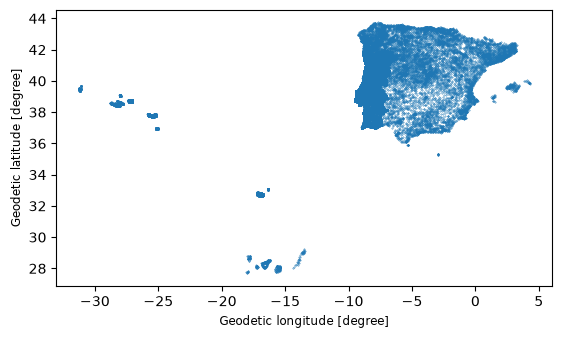

In [6]:
gdf_pc_PT_ES.plot(markersize=0.1);

## Localities (LAU)

In [7]:
gdf_loc = gpd.read_file(RAW_DIR / "LAU_RG_01M_2024_4326.gpkg")
gdf_loc.head()

,GISCO_ID,CNTR_CODE,LAU_NAME,POP_2024,POP_DENS_2024,AREA_KM2,YEAR,geometry
0,AL_AL141,AL,Kurbin,0.0,0.0,269.178779,2024,"POLYGON ((19.55733 41.57767, 19.57182 41.59103..."
1,AL_AL142,AL,Lezhë,0.0,0.0,509.342849,2024,"POLYGON ((19.8671 41.95292, 19.8707 41.94779, ..."
2,AL_AL143,AL,Mirditë,0.0,0.0,870.249553,2024,"POLYGON ((19.8671 41.95292, 19.87091 41.9601, ..."
3,AL_AL151,AL,Fushë Arrës,0.0,0.0,540.797778,2024,"POLYGON ((20.21865 42.19467, 20.22878 42.18531..."
4,AL_AL152,AL,Malësi e Madhe,0.0,0.0,951.441628,2024,"POLYGON ((19.78771 42.48755, 19.77704 42.47615..."


In [8]:
gdf_loc_PT_ES = gdf_loc[gdf_loc["CNTR_CODE"].isin(["PT", "ES"])].copy()

print("Records in Spain:", (gdf_loc_PT_ES["CNTR_CODE"] == "ES").sum())
print("POP_2024 values in PT:", gdf_loc_PT_ES.loc[gdf_loc_PT_ES["CNTR_CODE"] == "PT", "POP_2024"].unique()[:10])
print("POP_2024 values in ES:", gdf_loc_PT_ES.loc[gdf_loc_PT_ES["CNTR_CODE"] == "ES", "POP_2024"].unique()[:10])

Records in Spain: 8132
POP_2024 values in PT: [1700. 2218. 1280. 2021. 1556. 2848. 1842. 2915.  900. 1416.]
POP_2024 values in ES: [0.]


A population of 0 means the value is missing, so every 0 in `POP_2024` is replaced by a null value:

In [9]:
gdf_loc_PT_ES["POP_2024"] = gdf_loc_PT_ES["POP_2024"].replace(0, np.nan)

columns_to_drop = ["CNTR_CODE", "POP_DENS_2024", "YEAR"]
gdf_loc_PT_ES = gdf_loc_PT_ES.drop(columns=columns_to_drop)

new_column_names = {
    "GISCO_ID": "LocalityID",
    "LAU_NAME": "LocalityName",
    "POP_2024": "Population2024",
    "AREA_KM2": "AreaKm2",
}
gdf_loc_PT_ES = gdf_loc_PT_ES.rename(columns=new_column_names)
gdf_loc_PT_ES.head()

,LocalityID,LocalityName,Population2024,AreaKm2,geometry
27665,ES_04045,Fiñana,NaN,133.974442,"POLYGON ((-2.77558 37.2456, -2.77744 37.23836,..."
27666,ES_04046,Fondón,NaN,91.115877,"MULTIPOLYGON (((-2.88095 36.90501, -2.8837 36...."
27667,ES_04047,Gádor,NaN,87.668880,"POLYGON ((-2.44537 37.00978, -2.45847 37.00565..."
27668,ES_04048,"Gallardos, Los",NaN,34.847874,"POLYGON ((-1.90893 37.18733, -1.90371 37.17142..."
27669,ES_04049,Garrucha,NaN,7.667790,"POLYGON ((-1.84168 37.18804, -1.84581 37.19236..."


Two hierarchical identifiers are created from the first characters of `LocalityID` (e.g. `PT_010101` → `PT_0101` and `PT_01`). They allow localities to be grouped by municipality and district and linked to the CAOP tables.

*Note:* `MunicipalityID` and `DistrictID` are created for every locality, but they only match the CAOP tables for Portuguese records, because the CAOP covers Portugal only.

In [10]:
gdf_loc_PT_ES["MunicipalityID"] = gdf_loc_PT_ES["LocalityID"].str[:7]
gdf_loc_PT_ES["DistrictID"] = gdf_loc_PT_ES["LocalityID"].str[:5]

Some locality names are repeated, so a unique label `LocalityNameID` (name + ID) is created to avoid wrong matches in the Shape Map:

In [11]:
duplicates_loc = gdf_loc_PT_ES[gdf_loc_PT_ES.duplicated(subset="LocalityName", keep=False)]
print("Rows with repeated names:", len(duplicates_loc))

gdf_loc_PT_ES["LocalityNameID"] = gdf_loc_PT_ES["LocalityName"].astype(str) + " (" + gdf_loc_PT_ES["LocalityID"].astype(str) + ")"

print("Repeated LocalityNameID:", gdf_loc_PT_ES.duplicated(subset="LocalityNameID").sum())

Rows with repeated names: 464
Repeated LocalityNameID: 0


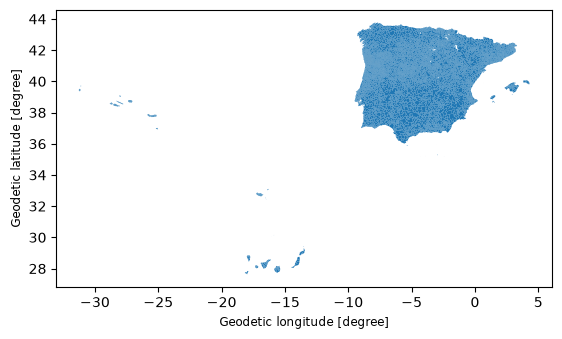

In [12]:
gdf_loc_PT_ES.plot();

## Add missing postal codes

Some postal codes are missing from the GISCO file. They are listed in `data/manual/missing_postal_codes.csv` with their coordinates. For each point, a spatial join assigns the NUTS and locality IDs of the polygon that contains it.

In [13]:
df_missing = pd.read_csv(MANUAL_DIR / "missing_postal_codes.csv", dtype={"PostalCode": str})

gdf_points = gpd.GeoDataFrame(
    df_missing,
    geometry=gpd.points_from_xy(df_missing["LonCent"], df_missing["LatCent"]),
    crs="EPSG:4326",
)

gdf_points = add_spatial_id(gdf_points, load_layer("NUTS3_2024_PT_ES"), "NUTS3_ID", "NUTS3_ID")
gdf_points = add_spatial_id(gdf_points, load_layer("NUTS2_2024_PT_ES"), "NUTS2_ID", "NUTS2_ID")
gdf_points = add_spatial_id(gdf_points, load_layer("NUTS1_2024_PT_ES"), "NUTS1_ID", "NUTS1_ID")
gdf_points = add_spatial_id(gdf_points, load_layer("NUTS0_2024_PT_ES"), "NUTS0_ID", "NUTS0_ID")
gdf_points = add_spatial_id(gdf_points, gdf_loc_PT_ES, "LocalityID", "LocalityID")

cols_check = ["NUTS3_ID", "NUTS2_ID", "NUTS1_ID", "NUTS0_ID", "LocalityID"]
no_match = gdf_points[cols_check].isna().any(axis=1)
if no_match.any():
    print("Points without a match (outside every polygon or invalid geometry):")
    print(gdf_points.loc[no_match, ["PostalCode", "LonCent", "LatCent"] + cols_check])

gdf_points

,PostalCode,LonCent,LatCent,geometry,NUTS3_ID,NUTS2_ID,NUTS1_ID,NUTS0_ID,LocalityID
0,1685-655,-9.196970,38.799030,POINT (-9.19697 38.79903),PT1A0,PT1A,PT1,PT,PT_111603
1,2710-738,-9.357890,38.793800,POINT (-9.35789 38.7938),PT1A0,PT1A,PT1,PT,PT_111128
2,7901-909,-8.734075,38.069141,POINT (-8.73408 38.06914),PT1C1,PT1C,PT1,PT,PT_150912
3,2405-000,-8.881317,39.693804,POINT (-8.88132 39.6938),PT193,PT19,PT1,PT,PT_100913
4,3840-000,-8.754075,40.559672,POINT (-8.75408 40.55967),PT191,PT19,PT1,PT,PT_011804
5,3060-302,-8.586251,40.481727,POINT (-8.58625 40.48173),PT191,PT19,PT1,PT,PT_011407
6,4425-000,-8.565017,41.211271,POINT (-8.56502 41.21127),PT11A,PT11,PT1,PT,PT_130601
7,3630-133,-7.403975,41.016600,POINT (-7.40398 41.0166),PT11D,PT11,PT1,PT,PT_181211


The degree of urbanisation is not known for these points, so `DegreeUrb` is left empty before joining them to the main table:

In [14]:
gdf_points["DegreeUrb"] = np.nan
gdf_points = gdf_points[gdf_pc_PT_ES.columns]

gdf_pc_PT_ES = gpd.GeoDataFrame(
    pd.concat([gdf_pc_PT_ES, gdf_points], ignore_index=True),
    crs=gdf_pc_PT_ES.crs,
)

# Validation: the new postal codes are now in the table
gdf_pc_PT_ES[gdf_pc_PT_ES["PostalCode"].isin(df_missing["PostalCode"])]

,PostalCode,NUTS3_ID,NUTS2_ID,NUTS1_ID,NUTS0_ID,LocalityID,DegreeUrb,geometry
209821,1685-655,PT1A0,PT1A,PT1,PT,PT_111603,NaN,POINT (-9.19697 38.79903)
209822,2710-738,PT1A0,PT1A,PT1,PT,PT_111128,NaN,POINT (-9.35789 38.7938)
209823,7901-909,PT1C1,PT1C,PT1,PT,PT_150912,NaN,POINT (-8.73408 38.06914)
209824,2405-000,PT193,PT19,PT1,PT,PT_100913,NaN,POINT (-8.88132 39.6938)
209825,3840-000,PT191,PT19,PT1,PT,PT_011804,NaN,POINT (-8.75408 40.55967)
209826,3060-302,PT191,PT19,PT1,PT,PT_011407,NaN,POINT (-8.58625 40.48173)
209827,4425-000,PT11A,PT11,PT1,PT,PT_130601,NaN,POINT (-8.56502 41.21127)
209828,3630-133,PT11D,PT11,PT1,PT,PT_181211,NaN,POINT (-7.40398 41.0166)


## Centroids, column order and save

In [15]:
gdf_pc_PT_ES = add_centroids(gdf_pc_PT_ES)[
    ["PostalCode", "NUTS3_ID", "NUTS2_ID", "NUTS1_ID", "NUTS0_ID", "LocalityID", "DegreeUrb",
     "LonCent", "LatCent", "geometry"]
]

gdf_loc_PT_ES = add_centroids(gdf_loc_PT_ES)[
    ["LocalityID", "MunicipalityID", "DistrictID", "LocalityName", "Population2024", "AreaKm2", "LocalityNameID",
     "LonCent", "LatCent", "geometry"]
]

save_layer(gdf_pc_PT_ES, "PostalCodes2024_PT_ES")
save_layer(gdf_loc_PT_ES, "Localities2024_PT_ES")

Saved layer 'PostalCodes2024_PT_ES' (209829 rows)
Saved layer 'Localities2024_PT_ES' (11224 rows)


## Summary
* **Postal codes:** kept PT and ES, removed unnecessary columns, renamed fields, cleaned the apostrophes in `NUTS3_ID` and derived `NUTS2_ID`, `NUTS1_ID` and `NUTS0_ID` from its prefixes.
* **Localities:** kept PT and ES, replaced population values of 0 by nulls, renamed fields, created `MunicipalityID` and `DistrictID`, and created `LocalityNameID` to deal with repeated names.
* **Missing postal codes:** added from a manual list, with their NUTS and locality IDs assigned by spatial join (`within`).
* Added centroids to both tables and saved them for the next notebooks.